In [117]:
import pandas as pd
import os
import re
import matplotlib.pyplot as plt
import seaborn as sns
import json

from pathlib import Path


In [118]:
PREFIX_RE = re.compile(
    r"^ortools_top(?P<total_genres>\d+)"
    r"_mintracks(?P<min_tracks>\d+)"
    r"_topcandidates(?P<top_candidates_per_song>\d+)"
    r"_genrepool(?P<candidate_genre_pool>\d+)"
    r"(?:_(?P<assignment_scope>interpretable))?"
    r"(?:_maxsongs(?P<max_songs>\d+))?"
    r"(?:_(?P<run_label>[A-Za-z0-9_-]+))?$"
)

def parse_prefix(prefix: str) -> dict | None:
    match = PREFIX_RE.match(prefix)
    if match is None:
        return None

    values = match.groupdict()
    max_songs = values.get("max_songs")
    return {
        "prefix": prefix,
        "total_genres": int(values["total_genres"]),
        "min_tracks": int(values["min_tracks"]),
        "top_candidates_per_song": int(values["top_candidates_per_song"]),
        "candidate_genre_pool": int(values["candidate_genre_pool"]),
        "assignment_scope": values.get("assignment_scope") or "all_modalities",
        "max_songs": int(max_songs) if max_songs is not None else None,
        "run_label": values.get("run_label"),
    }

In [119]:
PATHRUNS = Path("../../../data/processed/01_selected_genres_ortools/runs")
meta_data = "run_metadata.json"

N_WINDOWS = 61
MODALITIES = ["essentia", "lyrics_tf_idf", "metadata"]
N_MODALITIES = len(MODALITIES)

all_metadata = []

if PATHRUNS.exists():
    for path in PATHRUNS.iterdir():
        if not path.is_dir():
            continue

        result = parse_prefix(path.name)

        if result is not None:
            metadata_path = path / meta_data
            selected_genres_path = path / "selected_genres.csv"

            if metadata_path.exists():
                with open(metadata_path, "r", encoding="utf-8") as f:
                    metadata = json.load(f)

                metadata.update(result)

                if selected_genres_path.exists():
                    selected_genres = pd.read_csv(selected_genres_path)
                    metadata["selected_genre_count"] = len(selected_genres)
                else:
                    metadata["selected_genre_count"] = metadata["total_genres"]

                metadata["total_windows"] = N_WINDOWS
                metadata["total_modalities"] = N_MODALITIES

                all_metadata.append(metadata)

results = pd.json_normalize(all_metadata)

results["valid_coverage_pct"] = (
    results["solver.valid_cell_count"]
    / (
        results["selected_genre_count"]
        * results["total_windows"]
        * results["total_modalities"]
    )
    * 100
)

print(f"Loaded {len(results)} runs")
display(results)
file_folder = Path("../../../data/processed/final_summary_dataset")
results.to_csv(file_folder / "overview_dataset_results_all.csv")

Loaded 129 runs


,prefix,objective_version,assignment_scope,modalities_checked,total_genres,min_tracks,top_candidates_per_song,candidate_genre_pool,max_songs,run_label,...,outputs.coverage_summary,outputs.valid_windows,solver.ortools_version,solver.solver_parameters.max_time_in_seconds,solver.solver_parameters.num_search_workers,solver.solver_parameters.random_seed,solver.solver_parameters.log_search_progress,solver.solver_parameters.log_subsolver_statistics,solver.solver_response_stats,valid_coverage_pct
0,ortools_top50_mintracks30_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",50,30,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.606557
1,ortools_top50_mintracks100_topcandidates2_genr...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",50,100,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,44.590164
2,ortools_top50_mintracks25_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",50,25,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,68.000000
3,ortools_top75_mintracks15_topcandidates1_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",75,15,1,1000,None,NaN,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,59.781421
4,ortools_top45_mintracks10_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",45,10,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,80.109290
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124,ortools_top25_mintracks10_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,10,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.295082
125,ortools_top65_mintracks20_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",65,20,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,65.397226
126,ortools_top25_mintracks50_topcandidates3_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,50,3,1000,None,top3_comparison_time600,...,coverage_summary.csv,valid_windows.csv,9.15.6755,1200.0,24.0,42.0,True,True,CpSolverResponse summary:\nstatus: FEASIBLE\no...,74.032787
127,ortools_top30_mintracks30_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",30,30,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,76.174863


In [120]:
file_folder = Path("../../../data/processed/final_summary_dataset")

In [121]:
results_optimal = results[results["solver.solver_status"] == "OPTIMAL"]

group_cols = ["total_genres", "min_tracks"]

valid_combinations = (
    results_optimal[
        results_optimal["top_candidates_per_song"].isin([1, 2, 3])
    ]
    .groupby(group_cols)["top_candidates_per_song"]
    .agg(lambda x: {1, 2, 3}.issubset(set(x)))
)

valid_combinations = valid_combinations[valid_combinations].index

results_all_optimal = results_optimal[
    results_optimal.set_index(group_cols).index.isin(valid_combinations)
]

display(results_all_optimal.sort_values(group_cols + ["top_candidates_per_song"]))
results_all_optimal.to_csv(file_folder / "overview_dataset_results_optimal.csv")

,prefix,objective_version,assignment_scope,modalities_checked,total_genres,min_tracks,top_candidates_per_song,candidate_genre_pool,max_songs,run_label,...,outputs.coverage_summary,outputs.valid_windows,solver.ortools_version,solver.solver_parameters.max_time_in_seconds,solver.solver_parameters.num_search_workers,solver.solver_parameters.random_seed,solver.solver_parameters.log_search_progress,solver.solver_parameters.log_subsolver_statistics,solver.solver_response_stats,valid_coverage_pct
113,ortools_top25_mintracks10_topcandidates1_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,10,1,1000,None,NaN,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,86.557377
9,ortools_top25_mintracks10_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,10,2,1000,None,NaN,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.295082
124,ortools_top25_mintracks10_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,10,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,90.295082
55,ortools_top25_mintracks10_topcandidates3_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,10,3,1000,None,top3_comparison_time600,...,coverage_summary.csv,valid_windows.csv,9.15.6755,1200.0,24.0,42.0,True,True,CpSolverResponse summary:\nstatus: OPTIMAL\nob...,90.688525
60,ortools_top25_mintracks15_topcandidates1_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,15,1,1000,None,NaN,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,81.639344
30,ortools_top25_mintracks15_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,15,2,1000,None,NaN,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,87.016393
118,ortools_top25_mintracks15_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,15,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,87.016393
87,ortools_top25_mintracks15_topcandidates3_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,15,3,1000,None,top3_comparison_time600,...,coverage_summary.csv,valid_windows.csv,9.15.6755,1200.0,24.0,42.0,True,True,CpSolverResponse summary:\nstatus: OPTIMAL\nob...,87.868852
6,ortools_top25_mintracks20_topcandidates1_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,20,1,1000,None,NaN,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,77.967213
109,ortools_top25_mintracks20_topcandidates2_genre...,coverage_score_assigned_songs_v1,interpretable,"[essentia, lyrics_tf_idf, metadata]",25,20,2,1000,None,time600,...,coverage_summary.csv,valid_windows.csv,NaN,NaN,NaN,NaN,NaN,NaN,NaN,84.131148


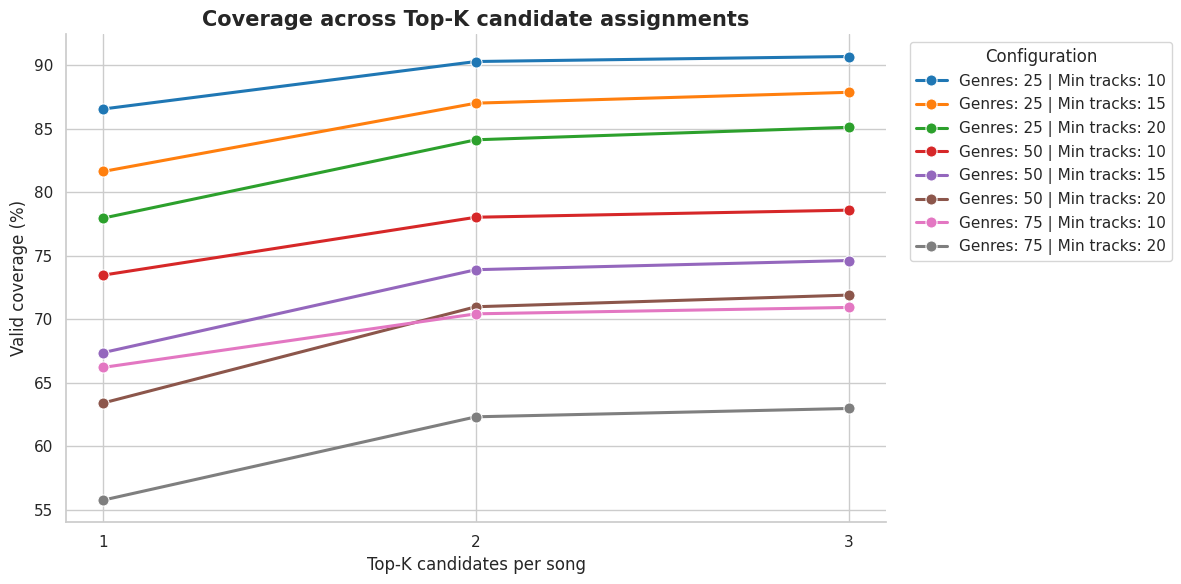

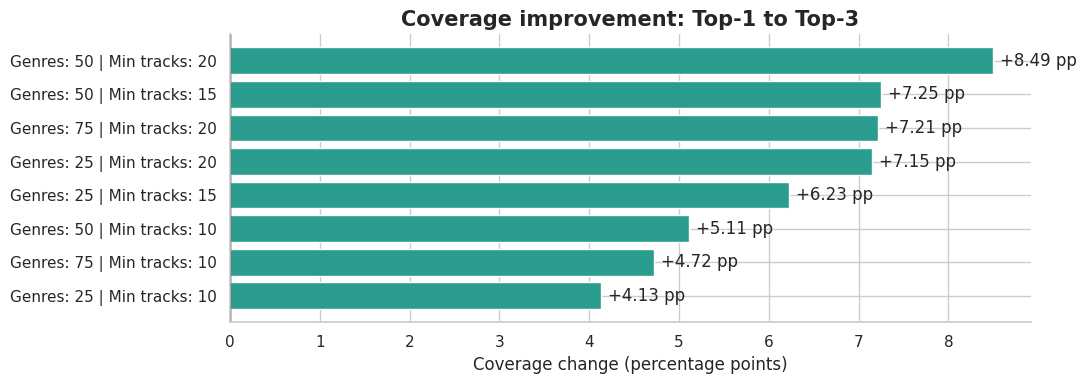

top_candidates_per_song,total_genres,min_tracks,1,2,3,improvement_1_to_3
5,50,20,63.409836,70.983607,71.901639,8.491803
4,50,15,67.377049,73.901639,74.622951,7.245902
7,75,20,55.759563,62.316940,62.972678,7.213115
2,25,20,77.967213,84.131148,85.114754,7.147541
1,25,15,81.639344,87.016393,87.868852,6.229508
3,50,10,73.475410,78.032787,78.590164,5.114754
6,75,10,66.207650,70.426230,70.928962,4.721311
0,25,10,86.557377,90.295082,90.688525,4.131148


In [122]:
OUTPUT_DIR = Path("plots")
group_cols = ["total_genres", "min_tracks"]
top_values = [1, 2, 3]

results_optimal = results[
    (results["solver.solver_status"] == "OPTIMAL") &
    (results["top_candidates_per_song"].isin(top_values))
].copy()

valid_combinations = (
    results_optimal
    .groupby(group_cols)["top_candidates_per_song"]
    .agg(lambda x: set(top_values).issubset(set(x)))
)

valid_combinations = valid_combinations[valid_combinations].index

results_all_optimal = results_optimal[
    results_optimal.set_index(group_cols).index.isin(valid_combinations)
].copy()

results_all_optimal["configuration"] = (
    "Genres: " + results_all_optimal["total_genres"].astype(str)
    + " | Min tracks: " + results_all_optimal["min_tracks"].astype(str)
)

coverage = (
    results_all_optimal
    .groupby(group_cols + ["top_candidates_per_song"], as_index=False)
    ["valid_coverage_pct"]
    .mean()
)

coverage["configuration"] = (
    "Genres: " + coverage["total_genres"].astype(str)
    + " | Min tracks: " + coverage["min_tracks"].astype(str)
)

sns.set_theme(style="whitegrid", context="notebook")

fig, ax = plt.subplots(figsize=(12, 6))

sns.lineplot(
    data=coverage,
    x="top_candidates_per_song",
    y="valid_coverage_pct",
    hue="configuration",
    marker="o",
    linewidth=2.2,
    markersize=8,
    palette="tab10",
    ax=ax
)

ax.set_title("Coverage across Top-K candidate assignments", fontsize=15, weight="bold")
ax.set_xlabel("Top-K candidates per song")
ax.set_ylabel("Valid coverage (%)")
ax.set_xticks(top_values)
ax.legend(title="Configuration", bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "optimal_topk_coverage_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

coverage_wide = coverage.pivot(
    index=group_cols,
    columns="top_candidates_per_song",
    values="valid_coverage_pct"
).dropna(subset=top_values)

coverage_wide["improvement_1_to_3"] = coverage_wide[3] - coverage_wide[1]

coverage_wide = coverage_wide.reset_index().sort_values("improvement_1_to_3")

coverage_wide["configuration"] = (
    "Genres: " + coverage_wide["total_genres"].astype(str)
    + " | Min tracks: " + coverage_wide["min_tracks"].astype(str)
)

fig, ax = plt.subplots(figsize=(11, max(4, len(coverage_wide) * 0.5)))

colors = [
    "#2a9d8f" if value >= 0 else "#e76f51"
    for value in coverage_wide["improvement_1_to_3"]
]

ax.barh(
    coverage_wide["configuration"],
    coverage_wide["improvement_1_to_3"],
    color=colors
)

ax.axvline(0, color="black", linewidth=1)

ax.set_title("Coverage improvement: Top-1 to Top-3", fontsize=15, weight="bold")
ax.set_xlabel("Coverage change (percentage points)")
ax.set_ylabel("")

for i, value in enumerate(coverage_wide["improvement_1_to_3"]):
    ax.annotate(
        f"{value:+.2f} pp",
        (value, i),
        xytext=(5 if value >= 0 else -5, 0),
        textcoords="offset points",
        ha="left" if value >= 0 else "right",
        va="center"
    )

sns.despine()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "optimal_top1_vs_top3_coverage_improvement.png", dpi=300, bbox_inches="tight")
plt.show()

display(
    coverage_wide[
        ["total_genres", "min_tracks", 1, 2, 3, "improvement_1_to_3"]
    ].sort_values("improvement_1_to_3", ascending=False)
)